# El frente eficiencia-uniformidad: cómo se ve el compromiso completo y quién está sobre él

**Pregunta:** ¿Cuál es el compromiso completo entre eficiencia de difracción y uniformidad en la tarea de 10 x 10 trampas, y algún método aislado del producto está sobre él?

- Nivel: 4, más allá del estado del arte (afirmación BS-5).
- Requisitos previos: `05-optimization/01-the-cost-and-its-gradient`, y `03-gerchberg-saxton/02-weights-for-uniformity` para los lazos que dan los puntos aislados.
- Tiempo de lectura: unos 30 minutos. El notebook se ejecuta en cerca de un minuto y medio.

## Objetivos

Cada método de la literatura informa su calidad como un par de números, una eficiencia y una uniformidad, y elegir entre métodos suele ser elegir entre pares. Pero un par es un punto de una curva: si cambia el peso de un costo, el número de iteraciones o la eficiencia objetivo, el mismo método cae en otro lugar. Este notebook pregunta cuál es la curva. Al terminar puedes:

- ubicar cualquier holograma de un arreglo de trampas en el plano de eficiencia y uniformidad, y decir qué significa dominar a otro;
- enunciar la pérdida que minimiza B5, y decir qué hacen sus dos términos y su parámetro $\lambda$;
- ejecutar los métodos de punto único del producto y la continuación que traza el frente, y leer ambos en una sola figura;
- decidir con los números si un método está sobre el frente, y cuánto le falta;
- poner a prueba la afirmación con una línea base más fuerte que la del benchmark, y decir qué sobrevive.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m04_gs, m05_gaa, m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b5_pareto
from pipeline.model.holo.methods.beyond.b5_pareto import hypervolume
from pipeline.model.holo.methods.optim import m09_direct_search, m11_wirtinger_adam

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C12 de `data/examples/cases.json`, la tarea de calibración que se usa en todo el tema de optimización.

- Propietario: este repositorio; el caso es sintético y sigue la tarea de 10 x 10 de Di Leonardo, Ianni y Ruocco (2007).
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C12.

In [2]:
# caso C12: el montaje óptico y las 100 trampas de la tarea de 10 x 10
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C12"]
setup = build.setup_of(rec)
target = build.target_of(rec)
print(rec["case_id"], "|", len(target.traps), "trampas | SLM", setup.n_pix, "x", setup.n_pix, "píxeles")

C12_calibration | 100 trampas | SLM 256 x 256 píxeles


## Método

### El plano y la pérdida

Sea $I_m$ la fracción de la potencia de entrada que llega a la trampa $m$. La eficiencia es $e = \sum_m I_m$ y la uniformidad es $u = 1 - (\max I - \min I) / (\max I + \min I)$ de las intensidades divididas por sus pesos objetivo (Di Leonardo et al., 2007). Un $e$ mayor y un $u$ mayor son ambos mejores, de modo que el holograma A domina al B cuando es al menos igual de bueno en ambos y estrictamente mejor en uno. El conjunto de hologramas que nadie domina es el frente de Pareto. Un método con un parámetro libre, como el peso $f$ del costo de Polin et al. (2005) o el número de iteraciones, traza una curva en este plano; un método sin parámetro da un punto.

B5 traza la curva con una continuación sobre una sola pérdida. Con $T_m = e_0 w_m / \sum_k w_k$ el objetivo de trampas iguales a la eficiencia $e_0$ de un holograma de partida,

$$L_\lambda(\phi) = (1 - \lambda)\,\frac{\sum_m (I_m - T_m)^2}{\sum_m T_m^2} \;-\; \lambda\,\frac{\sum_m I_m}{e_0}, \qquad \lambda \in [0, 1].$$

Con $\lambda = 0$ la pérdida pide trampas iguales a la eficiencia $e_0$ y nada más. Con $\lambda = 1$ pide solo luz, y la igualdad no se pide en absoluto. En medio cambia una por otra. B5 resuelve la pérdida para una malla de $\lambda$ de 0 a 1, cada vez con arranque en caliente desde la solución anterior, con gradiente conjugado, y conserva los resultados no dominados. Dividir los dos términos por $\sum T^2$ y por $e_0$ los hace adimensionales y de orden uno; esa escala es la lectura que el pipeline hace del dossier de investigación, que no declara ninguna. El hipervolumen es el área del plano, medida desde el origen, que dominan los puntos: un frente que domina más tiene mayor hipervolumen.

La primera celda ejecuta solo los dos extremos, $\lambda = 0$ y $\lambda = 1$, con 15 iteraciones de gradiente conjugado cada uno, para mostrar qué pide cada término antes de trazar la curva completa.

In [3]:
# los dos extremos de la pérdida: lambda = 0 pide trampas iguales, lambda = 1 pide solo luz
ends = b5_pareto.run(setup, target, budget=Budget(15), rng=Rng(1), n_lambda=2)
for lam, (eff, uni, sig) in zip(ends.meta["lambdas"], ends.meta["front"]):
    print(f"lambda {lam:.0f}: eficiencia {eff:.4f}  uniformidad {uni:.4f}  "
          f"desv. rel. {sig:.2f} %")
print(f"eficiencia del inicio (WGS de fase fija): {ends.meta['e0']:.4f}")

lambda 0: eficiencia 0.7921  uniformidad 0.9999  desv. rel. 0.00 %
lambda 1: eficiencia 0.8275  uniformidad 0.0003  desv. rel. 82.25 %
eficiencia del inicio (WGS de fase fija): 0.7921


Los dos extremos se comportan como dice la pérdida. Con $\lambda = 0$ el arreglo es perfectamente igual, con una desviación estándar relativa de 0,00 por ciento y una uniformidad de 0,9999, a una eficiencia de 0,7921, que es exactamente el $e_0$ del inicio. Con $\lambda = 1$ el optimizador subió la eficiencia a 0,8275 y renunció a la igualdad: la desviación estándar relativa es 82,25 por ciento y la uniformidad 0,0003, de modo que una trampa lleva casi toda la luz y otra casi nada. Los dos extremos están lejos en uniformidad, de 0,9999 a 0,0003, y cerca en eficiencia, de 0,7921 a 0,8275, una ganancia de 4,5 por ciento de la luz. Ese es el primer hecho sobre el frente, y las celdas siguientes lo miden con la curva completa: el compromiso en esta tarea es empinado, y casi todo se paga en uniformidad.

## Estado del arte

Los métodos de punto único son el estado del arte frente al que se mide B5. Cada uno se ejecuta aquí como la implementación propia del pipeline, con el presupuesto de 30 iteraciones del benchmark y la misma semilla: Gerchberg-Saxton simple (M04), el lazo aditivo adaptativo generalizado (M05) y el lazo ponderado (M06) de Di Leonardo et al. (2007), y el GS ponderado de fase fija (M07), el método para arreglos grandes de Kim et al. (2019). La primera celda ejecuta esos cuatro.

In [4]:
# cuatro métodos de proyección con el presupuesto de 30 iteraciones del benchmark, semilla 1
h04 = m04_gs.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
h05 = m05_gaa.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
h06 = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
h07 = m07_phase_fixed_wgs.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
for name, h in (("M04 GS", h04), ("M05 GAA", h05), ("M06 GSW", h06), ("M07 PF-WGS", h07)):
    print(f"{name:11s} eficiencia {h['efficiency']:.4f}  uniformidad {h['uniformity']:.4f}")

M04 GS      eficiencia 0.8105  uniformidad 0.6172
M05 GAA     eficiencia 0.8089  uniformidad 0.7053
M06 GSW     eficiencia 0.7971  uniformidad 0.9793
M07 PF-WGS  eficiencia 0.7914  uniformidad 0.9428


Dos puntos más vienen de la familia de optimización. La búsqueda directa (M09) cambia un píxel a la vez para bajar el costo de Polin et al. (2005), $C = -\langle I \rangle + f \sigma$, con $f = 0{,}5$; paga un precio en eficiencia por la uniformidad, por construcción. Wirtinger-Adam (M11), del notebook anterior, minimiza la pérdida cuadrática con pasos de gradiente.

In [5]:
# búsqueda directa (2 barridos de los píxeles) y Wirtinger-Adam (30 iteraciones), misma tarea y semilla
h09 = m09_direct_search.run(setup, target, budget=Budget(2), rng=Rng(1)).history[-1]
h11 = m11_wirtinger_adam.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
for name, h in (("M09 DS", h09), ("M11 Adam", h11)):
    print(f"{name:11s} eficiencia {h['efficiency']:.4f}  uniformidad {h['uniformity']:.4f}")

M09 DS      eficiencia 0.6584  uniformidad 0.9994
M11 Adam    eficiencia 0.7629  uniformidad 0.9327


La figura ubica los seis resultados en el plano de eficiencia y uniformidad.

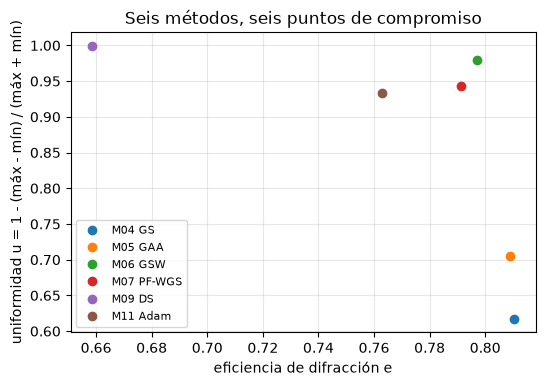

In [6]:
# los seis resultados puntuales en el plano de eficiencia y uniformidad
base = {"M04 GS": h04, "M05 GAA": h05, "M06 GSW": h06, "M07 PF-WGS": h07, "M09 DS": h09, "M11 Adam": h11}
fig, ax = plt.subplots(figsize=(6.0, 3.9))
for name, h in base.items():
    ax.plot(h["efficiency"], h["uniformity"], "o", label=name)
ax.set_xlabel("eficiencia de difracción e")
ax.set_ylabel("uniformidad u = 1 - (máx - mín) / (máx + mín)")
ax.set_title("Seis métodos, seis puntos de compromiso")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

Los seis puntos caen en tres grupos. M04 y M05 tienen la mayor eficiencia, 0,8105 y 0,8089, y la menor uniformidad, 0,6172 y 0,7053: son los lazos clásicos que ponen luz en las trampas y las dejan desiguales. M06 tiene una eficiencia de 0,7971 y una uniformidad de 0,9793, y M07 está en 0,7914 y 0,9428 tras las mismas 30 iteraciones; M11 está cerca de ellos, en 0,7629 y 0,9327. M09 está solo en el extremo uniforme, con una uniformidad de 0,9994 y una eficiencia de apenas 0,6584, que es el precio de su peso $f = 0{,}5$. La figura muestra seis puntos, y nada en ella dice si un punto podría subir o moverse a la derecha con el mismo método. No puede mostrar la curva que trazaría cada parámetro, y esa es la brecha que aborda B5: la literatura compara estos puntos, y ninguna fuente informa el frente completo en una misma tarea.

## Más allá del estado del arte

### El frente por continuación (BS-5)

La afirmación de B5 es que una continuación sobre una sola pérdida devuelve el frente completo al precio de unas pocas corridas de gradiente conjugado, y que ningún método de punto único está sobre él. La celda siguiente la ejecuta con 20 valores de $\lambda$ y 15 iteraciones de gradiente conjugado para cada uno, e imprime siete de los 20 puntos.

In [7]:
# el frente: 20 valores de lambda, 15 iteraciones de gradiente conjugado cada uno, cada uno desde su vecino
res_b5 = b5_pareto.run(setup, target, budget=Budget(15), rng=Rng(1))
front = res_b5.meta["front"]
for k in (0, 3, 6, 9, 12, 15, 19):
    print(f"lambda {res_b5.meta['lambdas'][k]:.2f}: eficiencia {front[k, 0]:.4f}  "
          f"uniformidad {front[k, 1]:.4f}  desv. rel. {front[k, 2]:.2f} %")
print(f"puntos que quedan como no dominados: {len(res_b5.meta['pareto'])} de {len(front)}")

lambda 0.00: eficiencia 0.7921  uniformidad 0.9999  desv. rel. 0.00 %
lambda 0.16: eficiencia 0.7993  uniformidad 0.9794  desv. rel. 0.83 %
lambda 0.32: eficiencia 0.8056  uniformidad 0.9539  desv. rel. 1.97 %
lambda 0.47: eficiencia 0.8085  uniformidad 0.9009  desv. rel. 3.62 %
lambda 0.63: eficiencia 0.8119  uniformidad 0.8228  desv. rel. 6.95 %
lambda 0.79: eficiencia 0.8168  uniformidad 0.7065  desv. rel. 12.83 %
lambda 1.00: eficiencia 0.8296  uniformidad 0.0085  desv. rel. 74.74 %
puntos que quedan como no dominados: 20 de 20


El frente es una curva, no una nube: los 20 puntos se conservan como no dominados. Su eficiencia va de 0,7921 a 0,8296 mientras su uniformidad va de 0,9999 a 0,0085, y la mayor parte de la pérdida de uniformidad llega al final de la curva, entre $\lambda = 0{,}79$ y $\lambda = 1$. Ahora la afirmación: para cada punto aislado, la celda cuenta los puntos del frente que lo dominan y lee la eficiencia que ofrece el frente con la misma uniformidad. La celda también compara el hipervolumen del frente con el de los puntos aislados, que es el criterio de aceptación de B5 en la escalera de métodos.

In [8]:
# para cada punto aislado: los puntos del frente que lo dominan y la eficiencia del frente con su uniformidad
by_uniformity = np.argsort(front[:, 1])
for name, h in base.items():
    e, u = h["efficiency"], h["uniformity"]
    better = (front[:, 0] >= e) & (front[:, 1] >= u) & ((front[:, 0] > e) | (front[:, 1] > u))
    offered = np.interp(u, front[by_uniformity, 1], front[by_uniformity, 0])
    print(f"{name:11s} dominado por {int(better.sum()):2d} puntos del frente | "
          f"eficiencia del frente con su uniformidad {offered:.4f} "
          f"frente a {e:.4f}")
pairs = {k: [h["efficiency"], h["uniformity"]] for k, h in base.items()}
hv_six = hypervolume(np.array(list(pairs.values())))
hv_four = hypervolume(np.array([pairs[k] for k in ("M04 GS", "M05 GAA", "M09 DS", "M06 GSW")]))
print(f"hipervolumen del frente: {res_b5.meta['hypervolume']:.4f}")
print(f"hipervolumen de los seis puntos: {hv_six:.4f} | de los cuatro del criterio: {hv_four:.4f}")

M04 GS      dominado por  5 puntos del frente | eficiencia del frente con su uniformidad 0.8189 frente a 0.8105
M05 GAA     dominado por  6 puntos del frente | eficiencia del frente con su uniformidad 0.8169 frente a 0.8089
M06 GSW     dominado por  1 puntos del frente | eficiencia del frente con su uniformidad 0.7993 frente a 0.7971
M07 PF-WGS  dominado por  8 puntos del frente | eficiencia del frente con su uniformidad 0.8064 frente a 0.7914
M09 DS      dominado por  1 puntos del frente | eficiencia del frente con su uniformidad 0.7922 frente a 0.6584
M11 Adam    dominado por  8 puntos del frente | eficiencia del frente con su uniformidad 0.8071 frente a 0.7629
hipervolumen del frente: 0.8180
hipervolumen de los seis puntos: 0.8032 | de los cuatro del criterio: 0.8032


La figura dibuja el frente y los seis puntos aislados juntos.

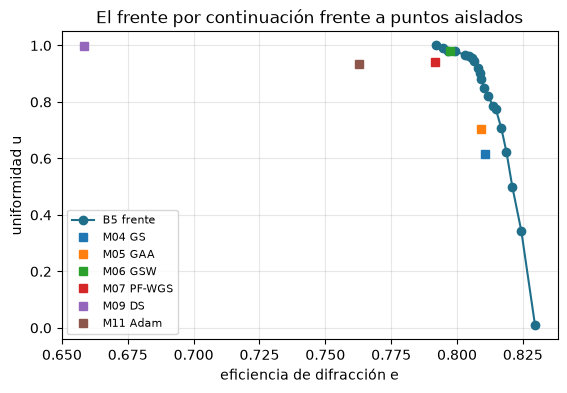

In [9]:
# el frente y los seis puntos en un mismo plano
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(front[:, 0], front[:, 1], "o-", color="#1f6f8b", label="B5 frente")
for name, h in base.items():
    ax.plot(h["efficiency"], h["uniformity"], "s", label=name)
ax.set_xlabel("eficiencia de difracción e")
ax.set_ylabel("uniformidad u")
ax.set_title("El frente por continuación frente a puntos aislados")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

Cada uno de los seis puntos aislados está dominado: entre 1 y 8 puntos del frente son al menos igual de buenos en ambas medidas y mejores en una. Los márgenes difieren mucho. Con la uniformidad de M09 el frente ofrece una eficiencia de 0,7922 frente a 0,6584, una ganancia de 0,1338 de la luz. Con la uniformidad de M07 ofrece 0,8064 frente a 0,7914, y para M11, 0,8071 frente a 0,7629. Para los lazos clásicos el margen es de cerca de 0,008, y para M06 es el menor, 0,7993 frente a 0,7971. El hipervolumen del frente es 0,8180 frente a 0,8032 de los seis puntos y de los cuatro del criterio, de modo que el criterio de aceptación de B5 se cumple. Lo que la figura no dice es cuán robusto es el margen de M06: 0,0022 de la luz es la diferencia entre un punto y la curva, y sale de una semilla y un presupuesto. El hipervolumen es además una herramienta tosca aquí, porque el origen está lejos y cada punto ya cubre cerca de 0,8 del cuadrado unitario.

### Una línea base más fuerte que la del benchmark

El benchmark fija 30 iteraciones para cada método, y el frente de arriba partió de un holograma de 30 iteraciones. Una prueba justa de una afirmación sobre un frente debe darle más esfuerzo a la línea base, ya que un método de punto único es una sola corrida. La línea base más fuerte para el extremo uniforme es el lazo ponderado M06, cuya uniformidad sigue mejorando con las iteraciones. La celda lo ejecuta 100 iteraciones y cuenta los puntos del frente que domina.

In [10]:
# la línea base puntual más fuerte: GS ponderado con 100 iteraciones en lugar de 30
res_long = m06_gsw.run(setup, target, budget=Budget(100), rng=Rng(1))
e_long, u_long = res_long.history[-1]["efficiency"], res_long.history[-1]["uniformity"]
beaten = (e_long >= front[:, 0]) & (u_long >= front[:, 1]) & ((e_long > front[:, 0]) | (u_long > front[:, 1]))
print(f"M06, 100 iteraciones: eficiencia {e_long:.4f}  uniformidad {u_long:.4f}")
print(f"puntos del frente que domina: {int(beaten.sum())} de {len(front)}")

M06, 100 iteraciones: eficiencia 0.8070  uniformidad 0.9946
puntos del frente que domina: 7 de 20


La afirmación falla en parte. Un holograma de GS ponderado de 100 iteraciones, con una eficiencia de 0,8070 y una uniformidad de 0,9946, domina 7 de los 20 puntos del frente: el frente subestima lo alcanzable en el extremo uniforme, porque su continuación partió de un inicio con una eficiencia de solo 0,7921 y gastó 15 iteraciones por valor. El frente no es una propiedad de la tarea sola sino de la tarea, el holograma de partida y el presupuesto. B5 acepta una fase inicial, así que la reparación es comenzar la continuación desde el holograma mejor. La celda lo hace con 8 valores de $\lambda$ y 30 iteraciones cada uno, e imprime los dos extremos del frente nuevo.

In [11]:
# la misma continuación iniciada desde ese holograma mejor: 8 valores de lambda, 30 iteraciones cada uno
res_warm = b5_pareto.run(setup, target, budget=Budget(30), rng=Rng(1), n_lambda=8, init=res_long.phi)
front_warm = res_warm.meta["front"]
print(f"extremo uniforme del frente nuevo: e {front_warm[0, 0]:.4f}  u {front_warm[0, 1]:.4f}")
print(f"extremo de eficiencia: e {front_warm[-1, 0]:.4f}  u {front_warm[-1, 1]:.4f}")
print(f"hipervolumen, frente nuevo: {res_warm.meta['hypervolume']:.4f} | "
      f"primer frente: {res_b5.meta['hypervolume']:.4f}")

extremo uniforme del frente nuevo: e 0.8070  u 1.0000
extremo de eficiencia: e 0.8318  u 0.0126
hipervolumen, frente nuevo: 0.8174 | primer frente: 0.8180


La figura dibuja ambos frentes y el punto de 100 iteraciones.

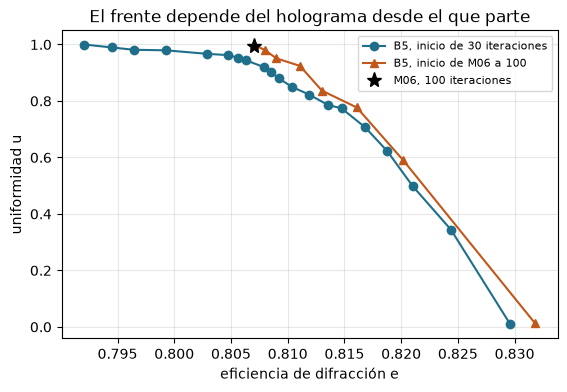

In [12]:
# ambos frentes y el punto del GS ponderado largo
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(front[:, 0], front[:, 1], "o-", color="#1f6f8b", label="B5, inicio de 30 iteraciones")
ax.plot(front_warm[:, 0], front_warm[:, 1], "^-", color="#c2571a", label="B5, inicio de M06 a 100")
ax.plot(e_long, u_long, "k*", markersize=11, label="M06, 100 iteraciones")
ax.set_xlabel("eficiencia de difracción e")
ax.set_ylabel("uniformidad u")
ax.set_title("El frente depende del holograma desde el que parte")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

El frente nuevo parte donde termina la línea base más fuerte: su extremo uniforme está en una eficiencia de 0,8070 y una uniformidad de 1,0000, lo que coincide con la eficiencia de M06 a 100 iteraciones en cuatro cifras y elimina el 0,0054 de no uniformidad que quedaba, y su extremo de eficiencia llega a 0,8318 frente a 0,8296 del primer frente. En la figura la curva naranja queda sobre la azul del lado uniforme y no queda bajo ella en ningún lugar que importe. El hipervolumen, 0,8174 con 8 valores de $\lambda$ frente a 0,8180 con 20, casi no se mueve, lo que confirma que no puede resolver esta diferencia. La figura no muestra que el frente nuevo sea el frente de Pareto verdadero de la tarea: solo muestra que el anterior no lo era. Un tercer inicio, o más iteraciones por valor, probablemente lo movería otra vez, y este notebook no tiene una estimación del límite. La afirmación segura es una dependencia: el frente que devuelve B5 es tan bueno como el holograma desde el que parte, y no mejor.

## Resultados

**Respuesta:** En la tarea de 10 x 10 el compromiso completo es una curva de 20 puntos no dominados que va de una eficiencia de 0,7921 y una uniformidad de 0,9999 a una eficiencia de 0,8296 y una uniformidad de 0,0085: gana 4,7 por ciento de la luz y pierde toda la uniformidad, de modo que el compromiso es empinado y se paga casi por completo en uniformidad. Ninguno de los seis métodos de punto único está sobre ella. Cada uno está dominado por entre 1 y 8 puntos del frente, M06 con el menor margen (el frente ofrece una eficiencia de 0,7993 con su uniformidad, frente a 0,7971), y el hipervolumen del frente, 0,8180, supera al de los seis puntos, 0,8032. La afirmación no sobrevive sin cambios a una línea base más fuerte: M06 con 100 iteraciones, en 0,8070 y 0,9946, domina 7 de los 20 puntos del frente. Iniciada desde ese holograma, la continuación da un frente cuyo extremo uniforme está en 0,8070 y 1,0000.

Lo que el notebook no establece es el frente verdadero de la tarea, solo se corrió una semilla, y el rango de eficiencia del frente es lo bastante pequeño como para que otro haz u otro número de trampas pudiera cambiar su forma.

## Resumen

- Un holograma es un punto en el plano de eficiencia y uniformidad, y un método con un parámetro libre es una curva; el frente es el conjunto que nadie domina.
- B5 lo traza por continuación sobre una sola pérdida, con $\lambda$ yendo de trampas iguales a solo luz, con arranque en caliente a lo largo.
- En esta tarea el frente es empinado: 4,7 por ciento más de luz cuesta toda la uniformidad.
- Con el presupuesto del benchmark ningún método de punto único está sobre el frente, con márgenes de 0,0022 a 0,1338 de la luz con igual uniformidad.
- El frente depende de su inicio y de su presupuesto: M06 con 100 iteraciones domina 7 de sus 20 puntos, y comenzar la continuación desde ese holograma repara el extremo uniforme.

## Referencias

- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Polin et al. (2005). Optimized holographic optical traps. Optics Express 13, 5831. https://doi.org/10.1364/OPEX.13.005831
- Kim et al. (2019). Large-scale uniform optical focus array generation with a phase spatial light modulator. Optics Letters 44, 3178. https://doi.org/10.1364/OL.44.003178